Date: 09-11-2026        

Subject: Machine Learning

Roll Number - Name :
                    
                    1)AP24110010563- K.Govardhana Krishna Sai
                    
                    2)AP24110010546 - Surendra Singh Chohan
                    
                    3)AP24110011059- P.Vijay

Regression method

In [29]:
from google.colab import files

uploaded = files.upload()

Saving Housing.csv to Housing (1).csv


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [31]:
df = pd.read_csv("Housing.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainr

In [32]:
X = df.drop(columns=["price"])
y = df["price"]

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:", list(numerical_features))
print("Categorical Features:", list(categorical_features))

Numerical Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical Features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [33]:
X = df.drop(columns=["price"])
y = df["price"]

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:", list(numerical_features))
print("Categorical Features:", list(categorical_features))

Numerical Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical Features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 436
Testing Records: 109


In [36]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [37]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,4060000,5263475.00
1,6650000,7284620.00
2,3710000,3777208.75
3,6440000,4485250.00
4,2800000,3798235.00
5,4900000,3451490.00
6,5250000,5114130.00
7,4543000,5308310.00
8,2450000,2541210.00
9,3353000,2902186.00


In [38]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("-----------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")

MODEL PERFORMANCE
-----------------------
MAE: 1026432.09
MSE: 1969991367460.95
RMSE: 1403563.81
R2 Score: 0.6103
R2 Percentage: 61.03 %


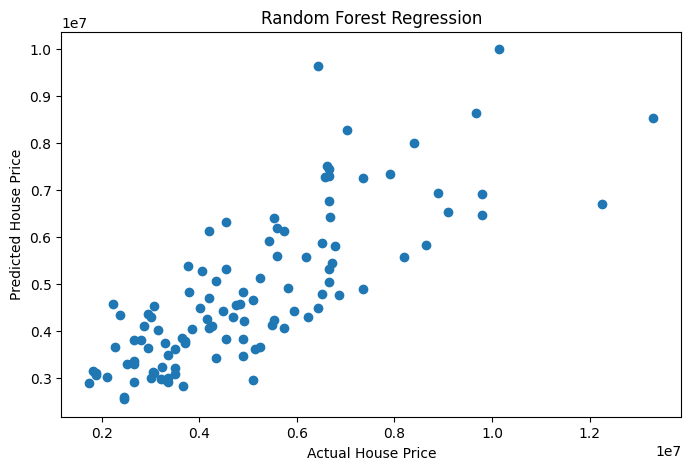

In [39]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")

plt.title("Random Forest Regression")

plt.show()

,Feature,Importance
15,num__area,0.464788
17,num__bathrooms,0.150715
19,num__parking,0.056402
18,num__stories,0.055832
16,num__bedrooms,0.046102
14,cat__furnishingstatus_unfurnished,0.033610
9,cat__airconditioning_yes,0.032079
8,cat__airconditioning_no,0.030290
4,cat__basement_no,0.016976
11,cat__prefarea_yes,0.016853


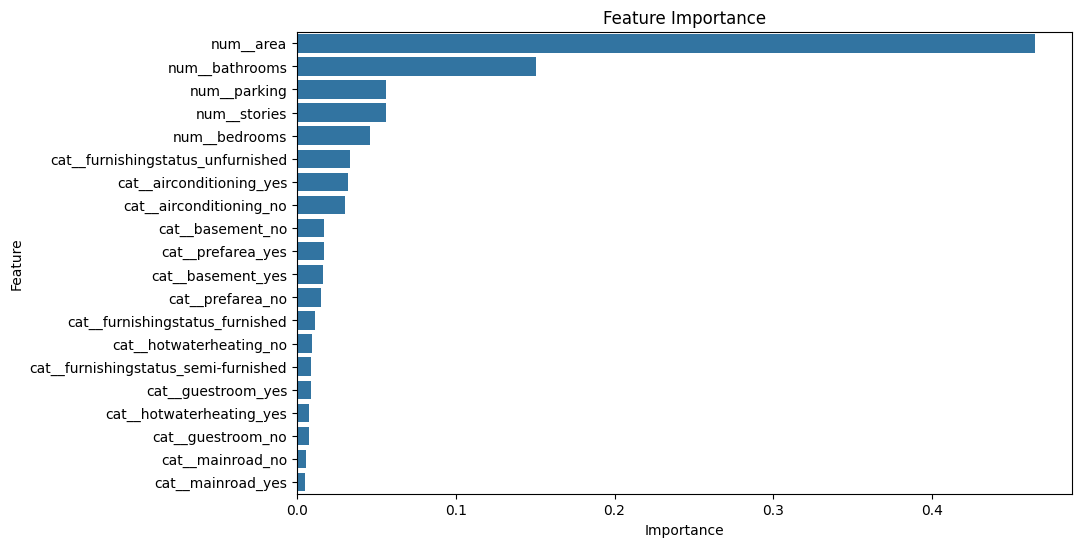

In [40]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = model.named_steps[
    "regressor"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")
plt.show()

In [41]:
new_house = pd.DataFrame([{
    "area": 5000,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "mainroad": "yes",
    "guestroom": "no",
    "basement": "yes",
    "hotwaterheating": "no",
    "airconditioning": "yes",
    "parking": 2,
    "prefarea": "yes",
    "furnishingstatus": "semi-furnished"
}])

prediction = model.predict(new_house)

print("Predicted House Price:", prediction[0])

Predicted House Price: 7236530.0


In [42]:
joblib.dump(model, "random_forest_house_model.pkl")

files.download("random_forest_house_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Classisfacation

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Housing.csv")

print("Dataset Shape:", df.shape)
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainr

In [44]:
df["price_category"] = pd.qcut(
    df["price"],
    q=3,
    labels=["Affordable", "Moderate", "Expensive"]
)

print(df[["price", "price_category"]].head(10))

print("\nCategory Distribution:")
print(df["price_category"].value_counts())

      price price_category
0  13300000      Expensive
1  12250000      Expensive
2  12250000      Expensive
3  12215000      Expensive
4  11410000      Expensive
5  10850000      Expensive
6  10150000      Expensive
7  10150000      Expensive
8   9870000      Expensive
9   9800000      Expensive

Category Distribution:
price_category
Affordable    186
Expensive     182
Moderate      177
Name: count, dtype: int64


In [45]:
df["price_category"] = pd.qcut(
    df["price"],
    q=3,
    labels=["Affordable", "Moderate", "Expensive"]
)

print(df[["price", "price_category"]].head(10))

print("\nCategory Distribution:")
print(df["price_category"].value_counts())

      price price_category
0  13300000      Expensive
1  12250000      Expensive
2  12250000      Expensive
3  12215000      Expensive
4  11410000      Expensive
5  10850000      Expensive
6  10150000      Expensive
7  10150000      Expensive
8   9870000      Expensive
9   9800000      Expensive

Category Distribution:
price_category
Affordable    186
Expensive     182
Moderate      177
Name: count, dtype: int64


In [46]:
X = df.drop(["price", "price_category"], axis=1)

y = df["price_category"]

print("Input Features:")
print(X.head())

print("\nTarget Classes:")
print(y.head())

Input Features:
   area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  7420         4          2        3      yes        no       no   
1  8960         4          4        4      yes        no       no   
2  9960         3          2        2      yes        no      yes   
3  7500         4          2        2      yes        no      yes   
4  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Target Classes:
0    Expensive
1    Expensive
2    Expensive
3    Expensive
4    Expensive
Name: price_category, dtype: category
Categories (3

In [47]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:", list(numerical_features))
print("Categorical Features:", list(categorical_features))

Numerical Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical Features: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),

        ("num", "passthrough", numerical_features)
    ]
)

print("Encoding completed!")

Encoding completed!


In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 436
Testing Records: 109


In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Random Forest Classification Model Trained Successfully!")

Random Forest Classification Model Trained Successfully!


In [51]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Category": y_test.values,
    "Predicted Category": y_pred
})

display(comparison.head(15))

,Actual Category,Predicted Category
0,Moderate,Moderate
1,Expensive,Expensive
2,Affordable,Moderate
3,Moderate,Affordable
4,Affordable,Affordable
5,Moderate,Affordable
6,Moderate,Moderate
7,Affordable,Affordable
8,Moderate,Moderate
9,Affordable,Moderate


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted"
)

recall = recall_score(
    y_test, y_pred, average="weighted"
)

f1 = f1_score(
    y_test, y_pred, average="weighted"
)

print("RANDOM FOREST CLASSIFICATION RESULTS")
print("------------------------------------")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

RANDOM FOREST CLASSIFICATION RESULTS
------------------------------------
Accuracy: 58.72 %
Precision: 0.6141
Recall: 0.5872
F1 Score: 0.5954

Classification Report:
              precision    recall  f1-score   support

  Affordable       0.68      0.62      0.65        37
   Expensive       0.73      0.59      0.66        37
    Moderate       0.42      0.54      0.47        35

    accuracy                           0.59       109
   macro avg       0.61      0.59      0.59       109
weighted avg       0.61      0.59      0.60       109



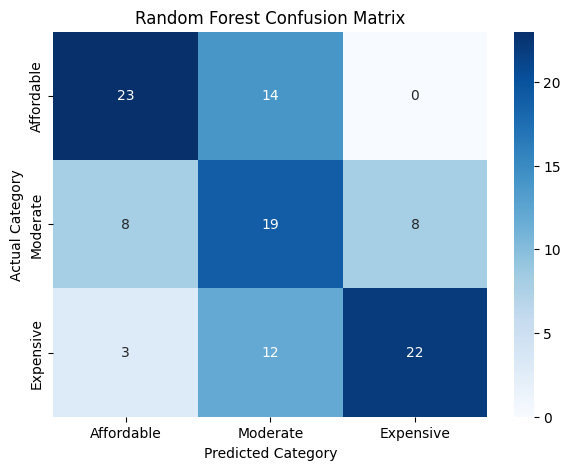

In [53]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Affordable", "Moderate", "Expensive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Affordable", "Moderate", "Expensive"],
    yticklabels=["Affordable", "Moderate", "Expensive"]
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Random Forest Confusion Matrix")

plt.show()

,Feature,Importance
15,num__area,0.278110
17,num__bathrooms,0.096196
18,num__stories,0.082117
16,num__bedrooms,0.069807
19,num__parking,0.064687
14,cat__furnishingstatus_unfurnished,0.053666
13,cat__furnishingstatus_semi-furnished,0.040250
9,cat__airconditioning_yes,0.037683
10,cat__prefarea_no,0.036432
8,cat__airconditioning_no,0.033233


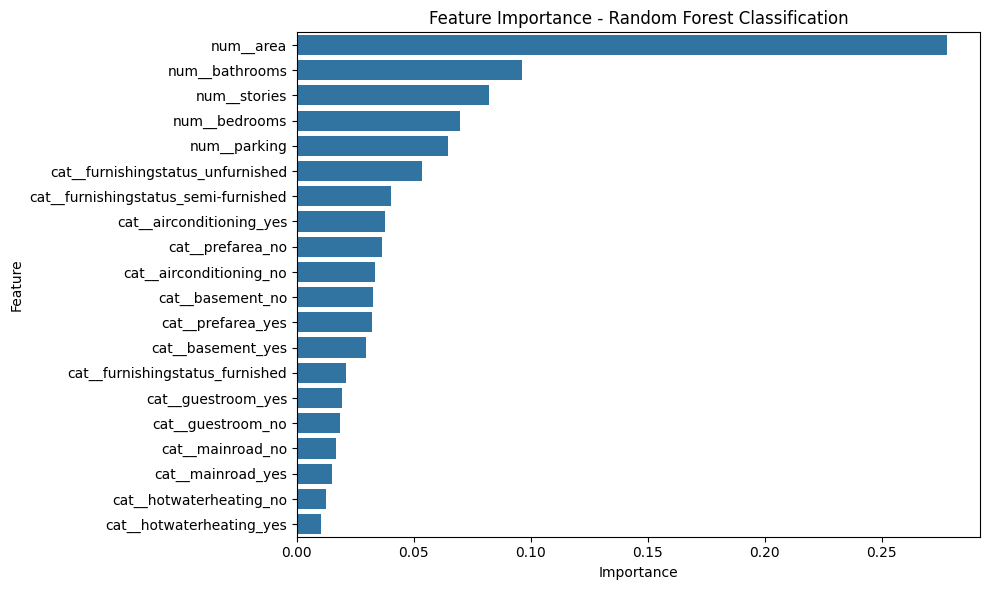

In [54]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest Classification")
plt.tight_layout()
plt.show()

In [55]:
new_house = pd.DataFrame([{
    "area": 5000,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "mainroad": "yes",
    "guestroom": "no",
    "basement": "yes",
    "hotwaterheating": "no",
    "airconditioning": "yes",
    "parking": 2,
    "prefarea": "yes",
    "furnishingstatus": "semi-furnished"
}])

prediction = model.predict(new_house)

print("Predicted House Price Category:", prediction[0])

Predicted House Price Category: Expensive


In [56]:
import joblib

joblib.dump(model, "house_price_classification_model.pkl")

print("Model saved successfully!")

from google.colab import files

files.download("house_price_classification_model.pkl")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>